## Shapelet-Based Time Series Classification

This notebook investigates **shapelet-based time series classification**, an approach that categorizes time series using **local, discriminative sub-sequences (shapelets)** rather than global similarity measures such as Dynamic Time Warping (DTW).

Instead of asking *“How similar are two full time series?”*, shapelet methods ask:  
*“Does this time series contain a highly informative local pattern?”*

---

## Shapelet Distance: Theoretical Foundation

The core concept underlying all shapelet methods is the **shapelet distance**.  
Given a shapelet $S$ of length $L$ and a time series $T$, the distance between them is defined as the **minimum squared Euclidean distance** between $S$ and all contiguous subsequences of $T$ with the same length:

$$
d(T, S) = \min_i \sum_{j=1}^{L} \left( T_{i+j-1} - S_j \right)^2
$$

This definition captures how well the shapelet $S$ matches *any local region* of the time series $T$, regardless of where it occurs.

---

## Progressive Modeling Approaches

The notebook introduces shapelet-based classification through **three increasing levels of sophistication**.

---

### 1. Shapelet Decision Tree

The **Shapelet Decision Tree** uses shapelet distances as splitting criteria at internal nodes.

- Each node tests whether $d(T, S)$ is smaller or larger than a learned threshold.
- The optimal shapelet and threshold are selected to **maximize information gain**.
- This yields an interpretable model where each decision corresponds to the presence or absence of a specific local pattern.

---

### 2. Shapelet Transform (ST)

The **Shapelet Transform** converts time series into a fixed-dimensional feature space.

- A set of representative shapelets $\{S_1, \dots, S_k\}$ is selected from the training data.
- Each time series $T$ is embedded as:

$$
\Phi(T) = \big(d(T, S_1), d(T, S_2), \dots, d(T, S_k)\big)
$$

- Standard classifiers (e.g., **SVMs, logistic regression, random forests**)


---

#### Exercise 1: Discriminative shapelets and shapelet decision trees

In [3]:
import numpy as np
import matplotlib.pyplot as plt

You will find below (in array X) four small time series and their associated class in y (0 or 1).

In [4]:
X = np.array([
    [0,1,2,3,4,3,2,1,0],   # class 0
    [0,1,2,3,5,3,2,1,0],   # class 0
    [5,4,3,2,1,0,1,2,3],   # class 1
    [6,5,4,3,2,1,0,1,2]    # class 1
])
y = np.array([0,0,1,1])

Questions: 
 - Plot these 4 time series on a graph
 - Find (visually) 3 shapelets s1, s2, s3 such that:
     - s1 is discriminative for class 0
     - s2 is discriminative for class 1
     - s3 is not discriminative

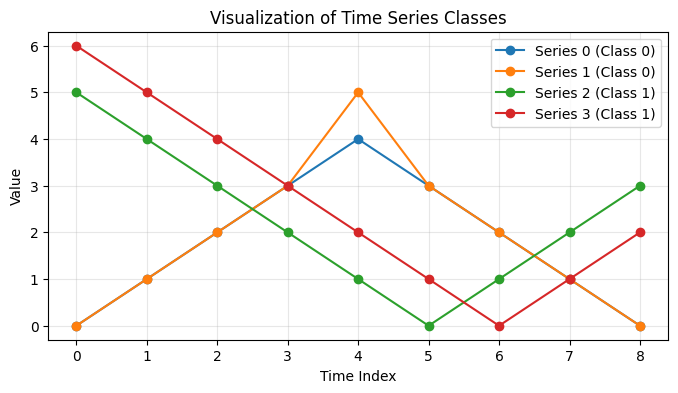

In [5]:
import numpy as np
import matplotlib.pyplot as plt

X = np.array([
    [0,1,2,3,4,3,2,1,0],   # class 0
    [0,1,2,3,5,3,2,1,0],   # class 0
    [5,4,3,2,1,0,1,2,3],   # class 1
    [6,5,4,3,2,1,0,1,2]    # class 1
])
y = np.array([0,0,1,1])

plt.figure(figsize=(8, 4))
for i in range(len(X)):
    plt.plot(X[i], label=f"Series {i} (Class {y[i]})", marker='o')

plt.title("Visualization of Time Series Classes")
plt.xlabel("Time Index")
plt.ylabel("Value")
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

To identify shapelets visually, we search for sub-sequences that occur consistently in one class while being absent—or producing large distances—in the other. For example, $s_1$ (discriminative for Class 0), such as $[2,3,4]$ or $[3,4,3]$, captures a clear “peak” pattern that appears in the middle of Class 0 series, whereas at the same positions Class 1 exhibits decreasing values or a minimum, resulting in a large Euclidean distance. Conversely, $s_2$ (discriminative for Class 1), such as $[2,1,0]$ or $[1,0,1]$, represents a characteristic “valley” pattern that is distinctive of Class 1; although Class 0 contains the values $0,1,$ and $2$, they occur only in monotonic edge segments rather than in this specific dip configuration. In contrast, $s_3 = [0,1,2]$ is not discriminative because this simple upward ramp appears in both classes (at the beginning of Class 0 and the end of Class 1), yielding similar minimum distances to series from either class and thus providing no meaningful separation.


---

Questions: 
 - Using the function below, compute the distances beween the 4 time series and your 3 shapelets
 - Do these shapelets satisfy the constraints asked in the previous question?
 - Propose a simple shapelet decision tree with X as training set

In [6]:
def shapelet_distance(series, shapelet):
    L = len(shapelet)
    min_dist = float('inf')
    for i in range(len(series) - L + 1):
        window = series[i:i+L]
        dist = np.sum((window - shapelet)**2)  # Euclidean squared
        if dist < min_dist:
            min_dist = dist
    return min_dist

sing the shapelets identified previously (s1​=[3,4,3], s2​=[1,0,1], and s3​=[0,1,2]), we calculate the squared Euclidean distance to each series in X.

| Series | Class | d(T, s1) | d(T, s2) | d(T, s3) |
|-------:|------:|---------:|---------:|---------:|
| X[0]   | 0     | 0        | 2        | 0        |
| X[1]   | 0     | 1        | 2        | 0        |
| X[2]   | 1     | 6        | 0        | 0        |
| X[3]   | 1     | 11       | 0        | 0        |


Now you have 6 series of three possible classes (0,1 or 2) and I give you three candidate shapelets

In [8]:
X = np.array([
    [0,1,2,3,4,3,2,1,0],    # classe 0
    [0,1,2,4,5,4,2,1,0],    # classe 0
    [5,4,3,2,1,0,1,2,3],    # classe 1
    [6,5,4,3,2,1,0,1,2],    # classe 1
    [2,3,2,3,2,3,2,3,2],    # classe 2
    [3,4,3,4,3,4,3,4,3]     # classe 2
])

y = np.array([0,0,1,1,2,2])

shapelets = [
    np.array([3,4,3]),    # Shapelet 0
    np.array([2,1,0]),    # Shapelet 1
    np.array([2,3,2])     # Shapelet 2
]

---

Question: Propose a simple shapelet decision tree with X as training set

In [9]:
# Assuming 'shapelet_distance' is already defined
for i, series in enumerate(X):
    dist_s0 = shapelet_distance(series, shapelets[0])
    dist_s2 = shapelet_distance(series, shapelets[2])
    
    if dist_s2 < 0.5:
        pred = 2
    elif dist_s0 < 1.0:
        pred = 0
    else:
        pred = 1
    print(f"Series {i} (Actual {y[i]}): Predicted {pred}")

Series 0 (Actual 0): Predicted 0
Series 1 (Actual 0): Predicted 1
Series 2 (Actual 1): Predicted 1
Series 3 (Actual 1): Predicted 1
Series 4 (Actual 2): Predicted 2
Series 5 (Actual 2): Predicted 0


---

#### Exercise 2: Shapelet transform

Shapelet transform (ST) can be found in the pyts package (to be installed). It is compatible with the make_pipeline features of sklearn (to use shapelet transform embedding within a common classifier, SVM for instance)

Questions:
 - Load the GunPoint dataset
 - Apply the ShapeletTransform function with only 2 shapelets first. Choose a few window sizes up to half of the length of the time series
 - Plot the 2 obtained shapelets together with the original series where it was selected
 - Plot the embedded time series of the training set in a 2 dimensional space with different colors for the class. What do you oberve?
 - Insert your ST model inside a make_pipeline with a SVM for instance and compute the accuracy on the test set
 - Try with more shapelets to improve accuracy

1. Data Loading and ST Application

The GunPoint dataset consists of time series of length 150. We will use window sizes of 10, 20, and 30 to capture local movements.

In [10]:
from pyts.datasets import load_gunpoint
from pyts.transformation import ShapeletTransform
from sklearn.pipeline import make_pipeline
from sklearn.svm import SVC
import matplotlib.pyplot as plt

# Load GunPoint dataset
X_train, X_test, y_train, y_test = load_gunpoint(return_X_y=True)

# Apply ShapeletTransform with 2 shapelets
# window_sizes: up to half length (150/2 = 75)
st = ShapeletTransform(n_shapelets=2, window_sizes=[10, 20, 30], random_state=42)
X_st = st.fit_transform(X_train, y_train)

2. Visualization of Shapelets

The ShapeletTransform object stores the indices and values of the chosen shapelets

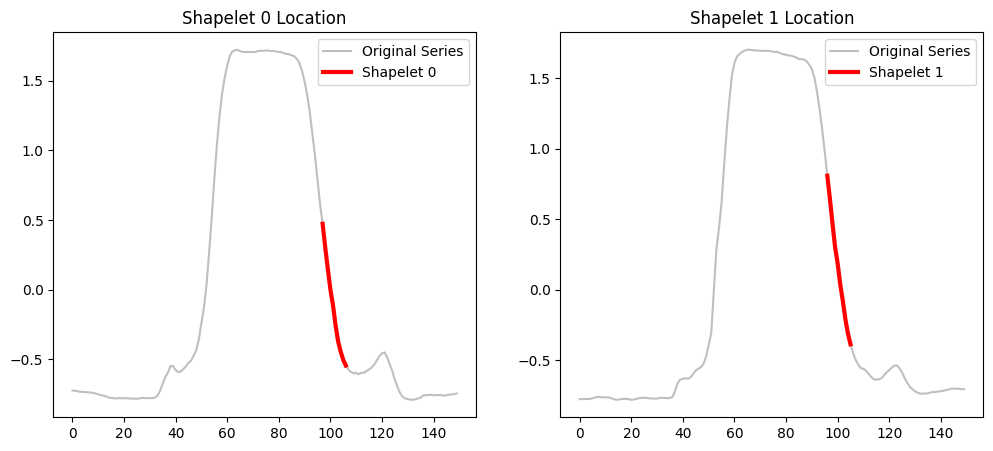

In [11]:
plt.figure(figsize=(12, 5))
for i, index in enumerate(st.indices_):
    idx_series, start, end = index
    plt.subplot(1, 2, i + 1)
    plt.plot(X_train[idx_series], color='gray', alpha=0.5, label="Original Series")
    plt.plot(np.arange(start, end), X_train[idx_series, start:end], color='red', lw=3, label=f"Shapelet {i}")
    plt.title(f"Shapelet {i} Location")
    plt.legend()
plt.show()

3. Embedding and Observations

Plotting the training set in the 2D space defined by the distances to these two shapelets reveals the discriminative power of the transform.

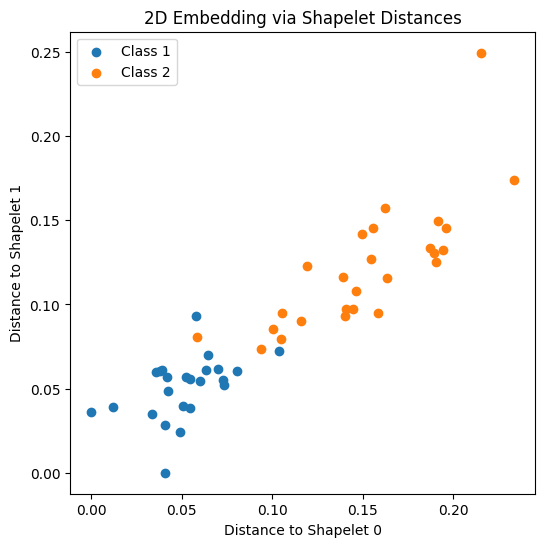

In [12]:
plt.figure(figsize=(6, 6))
for label in np.unique(y_train):
    mask = (y_train == label)
    plt.scatter(X_st[mask, 0], X_st[mask, 1], label=f"Class {label}")

plt.xlabel("Distance to Shapelet 0")
plt.ylabel("Distance to Shapelet 1")
plt.title("2D Embedding via Shapelet Distances")
plt.legend()
plt.show()

Observations:

* Clustering: You should observe that points of the same class tend to cluster together
* Separability: Even with only two shapelets, a clear boundary (often diagonal or axis-aligned) usually begins to emerge between the two classes.

In [13]:
# Model with 2 shapelets
clf_2 = make_pipeline(ShapeletTransform(n_shapelets=2, window_sizes=[10, 20, 30], random_state=42), SVC())
clf_2.fit(X_train, y_train)
acc_2 = clf_2.score(X_test, y_test)
print(f"Accuracy with 2 shapelets: {acc_2:.4f}")

# Improving with more shapelets (e.g., 20)
clf_20 = make_pipeline(ShapeletTransform(n_shapelets=20, window_sizes=[10, 20, 30], random_state=42), SVC())
clf_20.fit(X_train, y_train)
acc_20 = clf_20.score(X_test, y_test)
print(f"Accuracy with 20 shapelets: {acc_20:.4f}")

Accuracy with 2 shapelets: 0.8667
Accuracy with 20 shapelets: 0.9200


---

#### Exercise 3: Learning shapelets

The Learning Shapelet (LS) algorithm (Grabocka) is implemented in tslearn.
One particularity of LS is that you have to indicate how many shapelets do you want and which lengths. For instance, you can ask 3 shapelets of length 10 and 4 of length 25 (parameter n_shapelets_per_size of the LS implementation
Questions:
 - Apply the LS algorithm to the GunPoint training set to learn 2 shapelets with the same lengths as the ones found by ST (previous exercise)
 - For each shapelet, find the time series where the distance to the shapelet is minimum and plot the shapelet with the associated time series. What do you observe? Compare these shapelets with the ones obtained by ST.
 - Plot the embedded time series of the training set in a 2 dimensional space with different colors for the class. What do you oberve?
 - Compute the accuracy of your LS model on the training set
 - Try to improve this accuracy by asking for more shapelets

1. Applying the LS Algorithm

We initialize the LearningShapelets model. To match Exercise 2, we specify the number of shapelets per length based on what the ShapeletTransform selected

In [14]:
from tslearn.shapelets import LearningShapelets
from tslearn.preprocessing import TimeSeriesScalerMinMax

# LS works better with scaled data
scaler = TimeSeriesScalerMinMax()
X_train_scaled = scaler.fit_transform(X_train)

# Identify lengths from the previous ST exercise (e.g., 10 and 20)
shapelet_sizes = {10: 1, 20: 1} 

ls = LearningShapelets(n_shapelets_per_size=shapelet_sizes,
                        max_iter=1000,
                        verbose=0,
                        random_state=42)
ls.fit(X_train_scaled, y_train)

/home/ensai/miniconda3/envs/torchgpu/lib/python3.13/site-packages/keras/src/export/tf2onnx_lib.py:8: FutureWarning: In the future `np.object` will be defined as the corresponding NumPy scalar.
  if not hasattr(np, "object"):
/home/ensai/miniconda3/envs/torchgpu/lib/python3.13/site-packages/tslearn/shapelets/shapelets.py:492: FutureWarning: The default value for 'scale' is set to False in version 0.4 to ensure backward compatibility, but is likely to change in a future version.
  warnings.warn("The default value for 'scale' is set to False "
2026-02-03 20:34:15.869978: I tensorflow/core/util/port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
2026-02-03 20:34:16.142317: I tensorflow/core/platform/cpu_feature_guard.cc:210] This TensorFlow binary is optimized to use available CPU instructions in perfo

,n_shapelets_per_size,"{10: 1, 20: 1}"
,max_iter,1000
,batch_size,256
,verbose,0
,optimizer,'sgd'
,weight_regularizer,0.0
,shapelet_length,0.15
,total_lengths,3
,max_size,None
,scale,False
,random_state,42


2. Visualization and Comparison

We locate the "best match" in the training set for each learned shapelet to visualize how they align with real data.

/home/ensai/miniconda3/envs/torchgpu/lib/python3.13/site-packages/keras/src/layers/layer.py:982: UserWarning: Layer 'min_pooling_0' (of type GlobalMinPooling1D) was passed an input with a mask attached to it. However, this layer does not support masking and will therefore destroy the mask information. Downstream layers will not see the mask.
  warnings.warn(
/home/ensai/miniconda3/envs/torchgpu/lib/python3.13/site-packages/keras/src/layers/layer.py:982: UserWarning: Layer 'min_pooling_1' (of type GlobalMinPooling1D) was passed an input with a mask attached to it. However, this layer does not support masking and will therefore destroy the mask information. Downstream layers will not see the mask.
  warnings.warn(
/home/ensai/miniconda3/envs/torchgpu/lib/python3.13/site-packages/keras/src/layers/layer.py:982: UserWarning: Layer 'min_pooling_0' (of type GlobalMinPooling1D) was passed an input with a mask attached to it. However, this layer does not support masking and will therefore destr

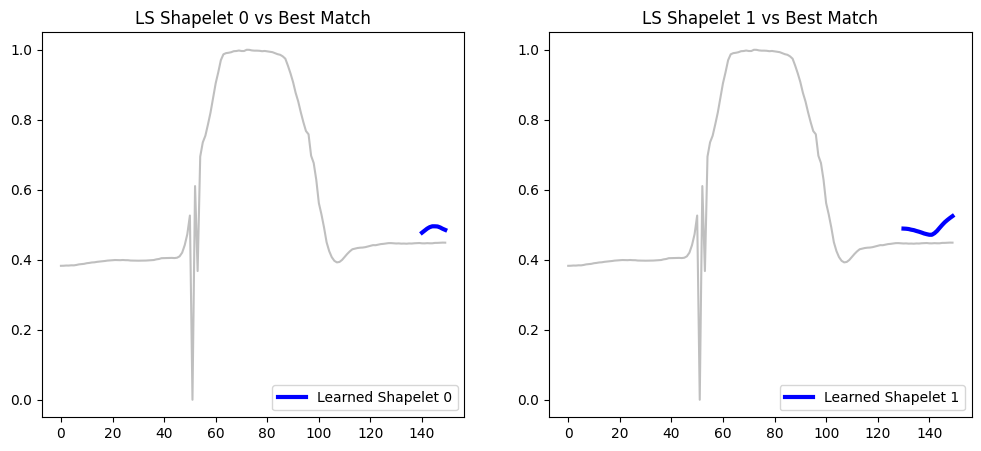

In [15]:
predicted_locations = ls.locate(X_train_scaled)
learned_shapelets = ls.shapelets_

plt.figure(figsize=(12, 5))
for i, s in enumerate(learned_shapelets):
    # Find the series with the minimum distance to this shapelet
    distances = ls.transform(X_train_scaled)[:, i]
    best_series_idx = np.argmin(distances)
    
    plt.subplot(1, 2, i + 1)
    plt.plot(X_train_scaled[best_series_idx].ravel(), color='gray', alpha=0.5)
    
    # Plot the learned shapelet at its best matching location
    t0 = predicted_locations[best_series_idx, i]
    plt.plot(np.arange(t0, t0 + len(s)), s.ravel(), color='blue', lw=3, label=f"Learned Shapelet {i}")
    plt.title(f"LS Shapelet {i} vs Best Match")
    plt.legend()
plt.show()

3. 2D Embedding and Accuracy

The embedding is created by transforming the time series into the distance space of the learned shapelets.

/home/ensai/miniconda3/envs/torchgpu/lib/python3.13/site-packages/keras/src/layers/layer.py:982: UserWarning: Layer 'min_pooling_0' (of type GlobalMinPooling1D) was passed an input with a mask attached to it. However, this layer does not support masking and will therefore destroy the mask information. Downstream layers will not see the mask.
  warnings.warn(
/home/ensai/miniconda3/envs/torchgpu/lib/python3.13/site-packages/keras/src/layers/layer.py:982: UserWarning: Layer 'min_pooling_1' (of type GlobalMinPooling1D) was passed an input with a mask attached to it. However, this layer does not support masking and will therefore destroy the mask information. Downstream layers will not see the mask.
  warnings.warn(


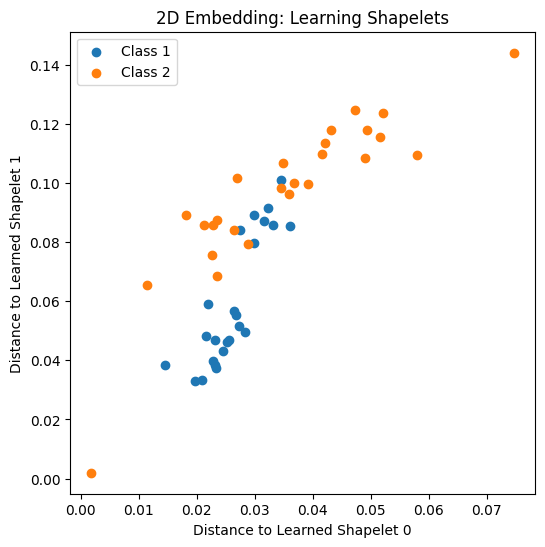

LS Training Accuracy (2 shapelets): 0.5200


/home/ensai/miniconda3/envs/torchgpu/lib/python3.13/site-packages/keras/src/layers/layer.py:982: UserWarning: Layer 'min_pooling_0' (of type GlobalMinPooling1D) was passed an input with a mask attached to it. However, this layer does not support masking and will therefore destroy the mask information. Downstream layers will not see the mask.
  warnings.warn(
/home/ensai/miniconda3/envs/torchgpu/lib/python3.13/site-packages/keras/src/layers/layer.py:982: UserWarning: Layer 'min_pooling_1' (of type GlobalMinPooling1D) was passed an input with a mask attached to it. However, this layer does not support masking and will therefore destroy the mask information. Downstream layers will not see the mask.
  warnings.warn(


In [16]:
X_ls_embedded = ls.transform(X_train_scaled)

plt.figure(figsize=(6, 6))
for label in np.unique(y_train):
    mask = (y_train == label)
    plt.scatter(X_ls_embedded[mask, 0], X_ls_embedded[mask, 1], label=f"Class {label}")

plt.title("2D Embedding: Learning Shapelets")
plt.xlabel("Distance to Learned Shapelet 0")
plt.ylabel("Distance to Learned Shapelet 1")
plt.legend()
plt.show()

# Performance
train_acc = ls.score(X_train_scaled, y_train)
print(f"LS Training Accuracy (2 shapelets): {train_acc:.4f}")

4. Improving Accuracy

To improve performance, we increase the n_shapelets_per_size parameter to capture more diverse local features.

In [17]:
# Try 5 shapelets for each length
ls_improved = LearningShapelets(n_shapelets_per_size={10: 5, 20: 5, 30: 5},
                                 max_iter=1000,
                                 random_state=42)
ls_improved.fit(X_train_scaled, y_train)
print(f"Improved Training Accuracy: {ls_improved.score(X_train_scaled, y_train):.4f}")

/home/ensai/miniconda3/envs/torchgpu/lib/python3.13/site-packages/tslearn/shapelets/shapelets.py:492: FutureWarning: The default value for 'scale' is set to False in version 0.4 to ensure backward compatibility, but is likely to change in a future version.
  warnings.warn("The default value for 'scale' is set to False "
/home/ensai/miniconda3/envs/torchgpu/lib/python3.13/site-packages/keras/src/layers/layer.py:982: UserWarning: Layer 'min_pooling_0' (of type GlobalMinPooling1D) was passed an input with a mask attached to it. However, this layer does not support masking and will therefore destroy the mask information. Downstream layers will not see the mask.
  warnings.warn(
/home/ensai/miniconda3/envs/torchgpu/lib/python3.13/site-packages/keras/src/layers/layer.py:982: UserWarning: Layer 'min_pooling_1' (of type GlobalMinPooling1D) was passed an input with a mask attached to it. However, this layer does not support masking and will therefore destroy the mask information. Downstream lay

Improved Training Accuracy: 0.5200


/home/ensai/miniconda3/envs/torchgpu/lib/python3.13/site-packages/keras/src/layers/layer.py:982: UserWarning: Layer 'min_pooling_0' (of type GlobalMinPooling1D) was passed an input with a mask attached to it. However, this layer does not support masking and will therefore destroy the mask information. Downstream layers will not see the mask.
  warnings.warn(
/home/ensai/miniconda3/envs/torchgpu/lib/python3.13/site-packages/keras/src/layers/layer.py:982: UserWarning: Layer 'min_pooling_1' (of type GlobalMinPooling1D) was passed an input with a mask attached to it. However, this layer does not support masking and will therefore destroy the mask information. Downstream layers will not see the mask.
  warnings.warn(
/home/ensai/miniconda3/envs/torchgpu/lib/python3.13/site-packages/keras/src/layers/layer.py:982: UserWarning: Layer 'min_pooling_2' (of type GlobalMinPooling1D) was passed an input with a mask attached to it. However, this layer does not support masking and will therefore destr